
# Lipinski's Rule of Five – Molecular Property Screener

## Project Overview

The physicochemical properties of a drug molecule strongly influence its potential for oral administration. Poor absorption is a common reason drug candidates fail, so early filters help save time and cost.

Lipinski’s Rule of Five (Lipinski et al., 1997) is an empirical guideline for judging the drug-likeness of small molecules. It was derived from orally administered drugs in clinical development. A molecule is likely to be orally active if it meets these criteria:

-  Molecular weight (MW) ≤ 500 Da
- Octanol–water partition coefficient (LogP) ≤ 5
- Hydrogen bond donors (HBD) ≤ 5
- Hydrogen bond acceptors (HBA) ≤ 10

In this project, a molecule is considered drug-like if it has no more than one violation.

This project applies the Rule of Five to 26 drug molecules using Python. The molecules come from my MSc coursework and span several therapeutic classes, including antibiotics, antidiabetics and antihypertensives. RDKit was used to calculate MW, LogP, HBD and HBA for each molecule. Pandas was used to tabulate the results and count violations. Matplotlib was used to plot molecular weight against LogP.
SMILES strings were taken from PubChem.


## Project Objective
To use basic cheminformatics tools to calculate molecular properties and make a preliminary assessment of drug-likeness for oral administration.

## Limitations
The Rule of Five is a screening guideline, not a predictor of oral bioavailability. It does not account for solubility, transport mechanisms or metabolism. Molecules that violate it can still be orally active.
HBD and HBA were counted with RDKit’s NumHDonors and NumHAcceptors. Lipinski’s original paper counted NH/OH groups and N/O atoms, which gives slightly higher counts.

In [48]:
pip install rdkit

In [49]:
pip install pandas

In [50]:
from rdkit import Chem

In [51]:
from rdkit.Chem import Descriptors

In [52]:
import pandas as pd


In [53]:
import matplotlib.pyplot as plt

In [54]:
data = {
    'name': ['penicillin G', 'metformin', 'chlorambucil', 'reserpine', 'vincristine', 'morphine', 'streptomycin', 'cephalosporin', 'pantozol', 'cetirizine', 'paracetamol', 'mupirocin', 'ranitidine', 'amoxicillin', 'minoxidil', 'clonidine', 'hydralazine', 'sorbitrate', 'atenolol', 'verapamil', 'tolbutamide', 'glipizide', 'miglitol', 'acyclovir', 'sitagliptin', 'moxifloxacin'],
    'smiles': [r'CC1(C(N2C(S1)C(C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C', r'CN(C)C(=N)N=C(N)N', r'C1=CC(=CC=C1CCCC(=O)O)N(CCCl)CCCl', r'CO[C@H]1[C@@H](C[C@@H]2CN3CCC4=C([C@H]3C[C@@H]2[C@@H]1C(=O)OC)NC5=C4C=CC(=C5)OC)OC(=O)C6=CC(=C(C(=C6)OC)OC)OC', r'CC[C@@]1(C[C@@H]2C[C@@](C3=C(CCN(C2)C1)C4=CC=CC=C4N3)(C5=C(C=C6C(=C5)[C@]78CCN9[C@H]7[C@@](C=CC9)([C@H]([C@@]([C@@H]8N6C=O)(C(=O)OC)O)OC(=O)C)CC)OC)C(=O)OC)O', r'CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@H]3[C@H](C=C4)O', r'C[C@H]1[C@@]([C@H]([C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H]([C@@H]([C@H]2O)O)N=C(N)N)O)N=C(N)N)O[C@H]3[C@H]([C@@H]([C@H]([C@@H](O3)CO)O)O)NC)(C=O)O', r'C=C1CS[C@@H](N=C1C(=O)O)[C@@H](C(=O)O)NC(=O)CCCC[C@H](C(=O)O)N', r'COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(F)F)OC', r'C1CN(CCN1CCOCC(=O)O)C(C2=CC=CC=C2)C3=CC=C(C=C3)Cl', r'CC(=O)NC1=CC=C(C=C1)O', r'C[C@H]([C@H]1[C@@H](O1)C[C@H]2CO[C@H]([C@@H]([C@@H]2O)O)C/C(=C/C(=O)OCCCCCCCCC(=O)O)/C)[C@H](C)O', r'CN/C(=C\[N+](=O)[O-])/NCCSCC1=CC=C(O1)CN(C)C', r'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=C(C=C3)O)N)C(=O)O)C', r'C1CCN(CC1)C2=NC(=N)N(C(=C2)N)O', r'C1CN=C(N1)NC2=C(C=CC=C2Cl)Cl', r'C1=CC=C2C(=C1)C=NN=C2NN', r'C1[C@H]([C@@H]2[C@H](O1)[C@H](CO2)O[N+](=O)[O-])O[N+](=O)[O-]', r'CC(C)NCC(COC1=CC=C(C=C1)CC(=O)N)O', r'CC(C)C(CCCN(C)CCC1=CC(=C(C=C1)OC)OC)(C#N)C2=CC(=C(C=C2)OC)OC', r'CCCCNC(=O)NS(=O)(=O)C1=CC=C(C=C1)C', r'CC1=CN=C(C=N1)C(=O)NCCC2=CC=C(C=C2)S(=O)(=O)NC(=O)NC3CCCCC3', r'C1[C@@H]([C@H]([C@@H]([C@H](N1CCO)CO)O)O)O', r'C1=NC2=C(N1COCCO)N=C(NC2=O)N', r'C1CN2C(=NN=C2C(F)(F)F)CN1C(=O)C[C@@H](CC3=CC(=C(C=C3F)F)F)N', 'COC1=C2C(=CC(=C1N3C[C@@H]4CCCN[C@@H]4C3)F)C(=O)C(=CN2C5CC5)C(=O)O']
}

In [55]:


data['smiles'] = [
    s.replace(r'\(', '(').replace(r'\)', ')').replace('\\\\', '\\')
    for s in data['smiles']
]

data['name'][0] = 'penicillin G'
data['name'][7] = 'cephalosporin C'
data['name'][8] = 'pantoprazole'
data['name'][17] = 'isosorbide dinitrate'

data['smiles'][7] = (
    'CC(=O)OCC1=C(N2[C@@H]([C@@H](C2=O)'
    'NC(=O)CCC[C@H](C(=O)O)N)SC1)C(=O)O'
)


from rdkit import Chem

for name, smiles in zip(data['name'], data['smiles']):
    mol = Chem.MolFromSmiles(smiles)
    print(name, 'Valid' if mol else 'Invalid')


penicillin G Valid
metformin Valid
chlorambucil Valid
reserpine Valid
vincristine Valid
morphine Valid
streptomycin Valid
cephalosporin C Valid
pantoprazole Valid
cetirizine Valid
paracetamol Valid
mupirocin Valid
ranitidine Valid
amoxicillin Valid
minoxidil Valid
clonidine Valid
hydralazine Valid
isosorbide dinitrate Valid
atenolol Valid
verapamil Valid
tolbutamide Valid
glipizide Valid
miglitol Valid
acyclovir Valid
sitagliptin Valid
moxifloxacin Valid


In [56]:
df = pd.DataFrame(data)


In [57]:
mols = [Chem.MolFromSmiles(smi) for smi in data['smiles']]

In [58]:
df['molecule'] = mols

In [59]:
df['molecular_weight'] = [Descriptors.MolWt(mol) for mol in df['molecule']]

In [60]:
df['LogP'] = [Descriptors.MolLogP(mol) for mol in df['molecule']]

In [61]:
df['hydrogen_donors'] = [Descriptors.NumHDonors(mol) for mol in df['molecule']]
df['hydrogen_acceptors'] = [Descriptors.NumHAcceptors(mol) for mol in df ['molecule']]

In [62]:
df

,name,smiles,molecule,molecular_weight,LogP,hydrogen_donors,hydrogen_acceptors
0,penicillin G,CC1(C(N2C(S1)C(C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C,<rdkit.Chem.rdchem.Mol object at 0x7a2b0a7852a0>,334.397,0.86080,2,4
1,metformin,CN(C)C(=N)N=C(N)N,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee0a0>,129.167,-1.24383,3,1
2,chlorambucil,C1=CC(=CC=C1CCCC(=O)O)N(CCCl)CCCl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aefae0>,304.217,3.37790,1,2
3,reserpine,CO[C@H]1[C@@H](C[C@@H]2CN3CCC4=C([C@H]3C[C@@H]...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec4a0>,608.688,4.17110,1,10
4,vincristine,CC[C@@]1(C[C@@H]2C[C@@](C3=C(CCN(C2)C1)C4=CC=C...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee260>,824.972,3.51750,3,12
5,morphine,CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aede00>,285.343,1.19810,2,4
6,streptomycin,C[C@H]1[C@@]([C@H]([C@@H](O1)O[C@@H]2[C@H]([C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee9d0>,581.580,-8.16110,12,15
7,cephalosporin C,CC(=O)OCC1=C(N2[C@@H]([C@@H](C2=O)NC(=O)CCC[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aeea40>,415.424,-1.12970,4,8
8,pantoprazole,COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec270>,383.376,2.88430,1,6
9,cetirizine,C1CN(CCN1CCOCC(=O)O)C(C2=CC=CC=C2)C3=CC=C(C=C3)Cl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aef6f0>,388.895,3.14820,1,4


In [63]:
molecular_weight = df['molecular_weight']

In [64]:
for weight in molecular_weight:
  if weight <= 500:
    print('pass')
  else:
    print('fail')


pass
pass
pass
fail
fail
pass
fail
pass
pass
pass
pass
fail
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass


In [65]:
new_molecular_weight = []
for weight in molecular_weight:
  if weight <= 500:
    new_molecular_weight.append('pass')
  else:
    new_molecular_weight.append('fail')

In [66]:
df['validation_molecular_weight'] = new_molecular_weight

In [67]:
logP = df['LogP']

In [68]:
for logp in logP:
  if logp <= 5:
    print('pass')
  else:
    print('fail')

pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
fail
pass
pass
pass
pass
pass
pass


In [69]:
new_logP = []
for logp in logP:
  if logp <= 5:
    new_logP.append('pass')
  else:
    new_logP.append('fail')

In [70]:
df['validation LogP'] = new_logP

In [71]:
hydrogen_donor = df['hydrogen_donors']

In [72]:
for donor in hydrogen_donor:
  if donor <= 5:
    print('pass')
  else:
    print('fail')

pass
pass
pass
pass
pass
pass
fail
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass


In [73]:
validation_hydrogen_donors=[]
for donor in hydrogen_donor:
  if donor <= 5:
    validation_hydrogen_donors.append('pass')
  else:
    validation_hydrogen_donors.append('fail')

In [74]:
df['validation_hydrogen_donors'] = validation_hydrogen_donors

In [75]:
Hydrogen_acceptors = df['hydrogen_acceptors']

In [76]:
for acceptors in Hydrogen_acceptors:
  if acceptors <= 10:
    print('pass')
  else:
    print('fail')

pass
pass
pass
pass
fail
pass
fail
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass
pass


In [77]:
new_hydrogen_acceptors = []
for acceptors in Hydrogen_acceptors:
  if acceptors <= 10:
    new_hydrogen_acceptors.append ('pass')
  else:
    new_hydrogen_acceptors.append ('fail')

In [78]:
df['validation_hydrogen_acceptors'] = new_hydrogen_acceptors

In [79]:

df

,name,smiles,molecule,molecular_weight,LogP,hydrogen_donors,hydrogen_acceptors,validation_molecular_weight,validation LogP,validation_hydrogen_donors,validation_hydrogen_acceptors
0,penicillin G,CC1(C(N2C(S1)C(C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C,<rdkit.Chem.rdchem.Mol object at 0x7a2b0a7852a0>,334.397,0.86080,2,4,pass,pass,pass,pass
1,metformin,CN(C)C(=N)N=C(N)N,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee0a0>,129.167,-1.24383,3,1,pass,pass,pass,pass
2,chlorambucil,C1=CC(=CC=C1CCCC(=O)O)N(CCCl)CCCl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aefae0>,304.217,3.37790,1,2,pass,pass,pass,pass
3,reserpine,CO[C@H]1[C@@H](C[C@@H]2CN3CCC4=C([C@H]3C[C@@H]...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec4a0>,608.688,4.17110,1,10,fail,pass,pass,pass
4,vincristine,CC[C@@]1(C[C@@H]2C[C@@](C3=C(CCN(C2)C1)C4=CC=C...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee260>,824.972,3.51750,3,12,fail,pass,pass,fail
5,morphine,CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aede00>,285.343,1.19810,2,4,pass,pass,pass,pass
6,streptomycin,C[C@H]1[C@@]([C@H]([C@@H](O1)O[C@@H]2[C@H]([C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee9d0>,581.580,-8.16110,12,15,fail,pass,fail,fail
7,cephalosporin C,CC(=O)OCC1=C(N2[C@@H]([C@@H](C2=O)NC(=O)CCC[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aeea40>,415.424,-1.12970,4,8,pass,pass,pass,pass
8,pantoprazole,COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec270>,383.376,2.88430,1,6,pass,pass,pass,pass
9,cetirizine,C1CN(CCN1CCOCC(=O)O)C(C2=CC=CC=C2)C3=CC=C(C=C3)Cl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aef6f0>,388.895,3.14820,1,4,pass,pass,pass,pass


In [80]:
violation_column = (df[['validation_molecular_weight','validation LogP','validation_hydrogen_donors','validation_hydrogen_acceptors']]=='fail').sum (axis=1)


In [81]:
df['number_of_violations'] = violation_column

In [82]:
no_of_violations = df['number_of_violations']

In [83]:
for  violation in no_of_violations:
  if violation > 1:
    print('oral-unlikely')
  else:
    print('oral-likely')

oral-likely
oral-likely
oral-likely
oral-likely
oral-unlikely
oral-likely
oral-unlikely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely
oral-likely


In [84]:
lipinski_approval=[]
for violation in no_of_violations:
  if violation > 1:
    lipinski_approval.append('oral-unlikely')
  else:
    lipinski_approval.append('oral-likely')


In [85]:
df['lipinski_approval'] = lipinski_approval

In [86]:
df

,name,smiles,molecule,molecular_weight,LogP,hydrogen_donors,hydrogen_acceptors,validation_molecular_weight,validation LogP,validation_hydrogen_donors,validation_hydrogen_acceptors,number_of_violations,lipinski_approval
0,penicillin G,CC1(C(N2C(S1)C(C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C,<rdkit.Chem.rdchem.Mol object at 0x7a2b0a7852a0>,334.397,0.86080,2,4,pass,pass,pass,pass,0,oral-likely
1,metformin,CN(C)C(=N)N=C(N)N,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee0a0>,129.167,-1.24383,3,1,pass,pass,pass,pass,0,oral-likely
2,chlorambucil,C1=CC(=CC=C1CCCC(=O)O)N(CCCl)CCCl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aefae0>,304.217,3.37790,1,2,pass,pass,pass,pass,0,oral-likely
3,reserpine,CO[C@H]1[C@@H](C[C@@H]2CN3CCC4=C([C@H]3C[C@@H]...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec4a0>,608.688,4.17110,1,10,fail,pass,pass,pass,1,oral-likely
4,vincristine,CC[C@@]1(C[C@@H]2C[C@@](C3=C(CCN(C2)C1)C4=CC=C...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee260>,824.972,3.51750,3,12,fail,pass,pass,fail,2,oral-unlikely
5,morphine,CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aede00>,285.343,1.19810,2,4,pass,pass,pass,pass,0,oral-likely
6,streptomycin,C[C@H]1[C@@]([C@H]([C@@H](O1)O[C@@H]2[C@H]([C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aee9d0>,581.580,-8.16110,12,15,fail,pass,fail,fail,3,oral-unlikely
7,cephalosporin C,CC(=O)OCC1=C(N2[C@@H]([C@@H](C2=O)NC(=O)CCC[C@...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aeea40>,415.424,-1.12970,4,8,pass,pass,pass,pass,0,oral-likely
8,pantoprazole,COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(...,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aec270>,383.376,2.88430,1,6,pass,pass,pass,pass,0,oral-likely
9,cetirizine,C1CN(CCN1CCOCC(=O)O)C(C2=CC=CC=C2)C3=CC=C(C=C3)Cl,<rdkit.Chem.rdchem.Mol object at 0x7a2b07aef6f0>,388.895,3.14820,1,4,pass,pass,pass,pass,0,oral-likely


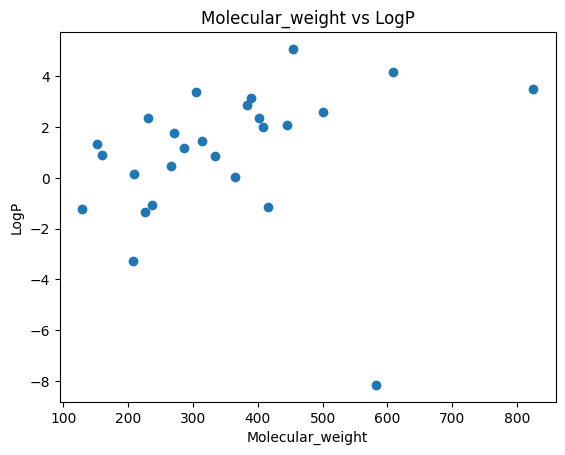

In [87]:
x = df['molecular_weight']
y = df['LogP']
plt.scatter (x,y)
plt.xlabel('Molecular_weight')
plt.ylabel('LogP')
plt.title('Molecular_weight vs LogP')
plt.show()

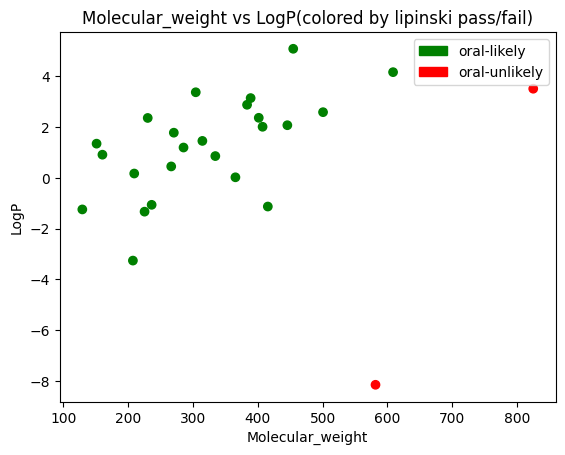

In [88]:
import matplotlib.patches as mpatches
plt.scatter(x,y,c=df['lipinski_approval'].map({'oral-likely' :'green', 'oral-unlikely':'red'}))
plt.xlabel ('Molecular_weight')
plt.ylabel ('LogP')
plt.title ('Molecular_weight vs LogP(colored by lipinski pass/fail)')
plt.legend(handles=[
    mpatches.Patch(color='green', label='oral-likely'),
    mpatches.Patch(color='red', label='oral-unlikely')
])
plt.show()


Conclusion

Of the 26 molecules screened, 21 met all four criteria, 3 had one violation and 2 had two or more. Streptomycin had three violations: molecular weight (581.58 Da), hydrogen bond donors (12) and hydrogen bond acceptors (15). Vincristine had two: molecular weight (824.97 Da) and hydrogen bond acceptors (12). Reserpine (MW 608.69 Da), mupirocin (MW 500.63 Da) and verapamil (LogP 5.09) each had one violation, so they still count as drug-like under the one-violation cut-off.

The MW–LogP plot shows a weak positive trend: heavier molecules generally had higher LogP. Streptomycin is a clear outlier, with a high molecular weight but a very low LogP (-8.16). The two oral-unlikely molecules, vincristine and streptomycin, sit at the high-MW end of the plot.

Some flagged molecules, such as reserpine and verapamil, are known orally active drugs. This shows that the rule is a preliminary filter and cannot confirm bioavailability on its own. Vincristine and streptomycin are given by injection, which fits their oral-unlikely result.

Future work could add TPSA and rotatable bond filters (Veber’s rules) and extend the analysis to a larger dataset such as ChEMBL.